# Notebook 01c — Union Corpus Build

**Project:** Scènes à Faire Computational Framework (v4 rebuild)  
**Purpose:** Merge the audited CMU and Kaggle corpora into a single deduplicated union corpus with provenance tracking.

**Why:** Notebook 01b showed that CMU and Kaggle have only 41% overlap. They're substantially complementary: CMU is stronger for the 1960s–2000s, Kaggle is stronger for the 1940s–1950s and the 2010s. The union is roughly 46,000 unique films, larger and more temporally complete than either corpus alone.

**Deduplication strategy:**
1. Normalize titles (lowercase, strip punctuation and parentheticals)
2. Match on `(normalized_title, year)` with ±1 year slack to handle Wikipedia date drift
3. When a film exists in both corpora, keep CMU's plot text (better-curated in the original CMU paper) but inherit Kaggle's metadata where CMU is missing
4. Tag every row with `corpus_source` ∈ {'cmu', 'kaggle', 'both'} so we can run replication checks later

**Output:** `movies_union.parquet` with provenance column. This is the primary corpus for Notebook 02 (element extraction).

## 1. Setup

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import re
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 100
plt.rcParams['figure.facecolor'] = 'white'
pd.set_option('display.max_colwidth', 120)

In [ ]:
PROJECT_ROOT = '/content/drive/MyDrive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational'

CMU_PATH = f'{PROJECT_ROOT}/v4_rebuild/01_audit/cmu_audited.parquet'
KAGGLE_PATH = f'{PROJECT_ROOT}/v4_rebuild/01b_audit_kaggle/kaggle_audited.parquet'

OUTPUT_DIR = f'{PROJECT_ROOT}/v4_rebuild/01c_union'
FIGURES_DIR = f'{OUTPUT_DIR}/figures'

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

assert os.path.exists(CMU_PATH), f'CMU parquet missing. Run Notebook 01 first.'
assert os.path.exists(KAGGLE_PATH), f'Kaggle parquet missing. Run Notebook 01b first.'

print('All inputs found.')

All inputs found.


## 2. Load Both Corpora

In [ ]:
cmu = pd.read_parquet(CMU_PATH)
kaggle = pd.read_parquet(KAGGLE_PATH)

print(f'CMU:    {len(cmu):,} films, columns: {list(cmu.columns)}')
print(f'Kaggle: {len(kaggle):,} films, columns: {list(kaggle.columns)}')

# Tag with source before any merging
cmu['source_raw'] = 'cmu'
kaggle['source_raw'] = 'kaggle'

CMU:    35,249 films, columns: ['wiki_id', 'name', 'year', 'decade', 'plot', 'char_count', 'word_count', 'token_count', 'genres_parsed', 'genres_canonical', 'n_canonical_genres', 'languages', 'countries']
Kaggle: 25,924 films, columns: ['wiki_id', 'name', 'year', 'decade', 'plot', 'char_count', 'word_count', 'token_count', 'genres_parsed', 'genres_canonical', 'n_canonical_genres', 'origin', 'director']


## 3. Normalize Titles for Matching

Wikipedia movie titles have a lot of variance: parentheticals like "(1990 film)", punctuation differences, capitalization, stray whitespace. We normalize aggressively so that "The Godfather (1972)" and "the godfather" match.

In [ ]:
def normalize_title(t):
    """Aggressive title normalization for cross-corpus matching."""
    if pd.isna(t):
        return ''
    t = str(t).lower()
    t = re.sub(r'\(.*?\)', '', t)          # drop parentheticals
    t = re.sub(r'[^a-z0-9\s]', '', t)       # strip punctuation
    t = re.sub(r'\s+', ' ', t).strip()
    # Drop leading articles to catch 'The Godfather' == 'Godfather'
    for article in ['the ', 'a ', 'an ']:
        if t.startswith(article):
            t = t[len(article):]
            break
    return t

cmu['title_norm'] = cmu['name'].apply(normalize_title)
kaggle['title_norm'] = kaggle['name'].apply(normalize_title)

cmu['year_int'] = cmu['year'].fillna(-1).astype(int)
kaggle['year_int'] = kaggle['year'].fillna(-1).astype(int)

# Sanity: how many films lose their title under normalization?
cmu_empty = (cmu['title_norm'] == '').sum()
kag_empty = (kaggle['title_norm'] == '').sum()
print(f'CMU films with empty normalized title:    {cmu_empty}')
print(f'Kaggle films with empty normalized title: {kag_empty}')

# Show a few examples of normalization
print('\nNormalization examples (CMU):')
for _, row in cmu.sample(5, random_state=7).iterrows():
    print(f'  "{row["name"]}" -> "{row["title_norm"]}"')

CMU films with empty normalized title:    4
Kaggle films with empty normalized title: 0

Normalization examples (CMU):
  "Dark Streets" -> "dark streets"
  "Batman & Robin" -> "batman robin"
  "Hollywood" -> "hollywood"
  "Nirbachana" -> "nirbachana"
  "Hansel and Gretel" -> "hansel and gretel"


## 4. Build Match Index

Strategy: for every CMU film, check if there exists a Kaggle film with the same normalized title AND a year within ±1 of the CMU year. Return the Kaggle index if matched. This handles Wikipedia date drift where the same film is listed under slightly different years in the two source scrapes.

In [ ]:
# Build a dict: title_norm -> list of (kaggle_idx, year_int)
kaggle_title_index = defaultdict(list)
for idx, row in kaggle.iterrows():
    if row['title_norm']:
        kaggle_title_index[row['title_norm']].append((idx, row['year_int']))

print(f'Kaggle title index built: {len(kaggle_title_index):,} unique normalized titles')
print(f'Avg entries per title: {sum(len(v) for v in kaggle_title_index.values()) / len(kaggle_title_index):.2f}')

Kaggle title index built: 24,165 unique normalized titles
Avg entries per title: 1.07


In [ ]:
# For each CMU film, find a matching Kaggle film (±1 year)
cmu['kaggle_match_idx'] = -1  # -1 means no match

for cmu_idx, row in cmu.iterrows():
    t = row['title_norm']
    y = row['year_int']
    if not t or y == -1:
        continue
    candidates = kaggle_title_index.get(t, [])
    for kag_idx, kag_year in candidates:
        if kag_year == -1:
            continue
        if abs(kag_year - y) <= 1:
            cmu.at[cmu_idx, 'kaggle_match_idx'] = kag_idx
            break

matched = (cmu['kaggle_match_idx'] >= 0).sum()
print(f'CMU films matched to Kaggle: {matched:,} ({matched/len(cmu)*100:.1f}% of CMU)')
print(f'CMU films unique to CMU:     {len(cmu) - matched:,}')

# Identify Kaggle films that were matched (so we know which are unique to Kaggle)
matched_kaggle_idxs = set(cmu.loc[cmu['kaggle_match_idx'] >= 0, 'kaggle_match_idx'])
kaggle['is_matched'] = kaggle.index.isin(matched_kaggle_idxs)
unique_kaggle = (~kaggle['is_matched']).sum()
print(f'Kaggle films unique to Kaggle: {unique_kaggle:,} ({unique_kaggle/len(kaggle)*100:.1f}% of Kaggle)')

print(f'\nUnion size (unique films): {len(cmu) + unique_kaggle:,}')

CMU films matched to Kaggle: 15,285 (43.4% of CMU)
CMU films unique to CMU:     19,964
Kaggle films unique to Kaggle: 10,709 (41.3% of Kaggle)

Union size (unique films): 45,958


## 5. Build the Union DataFrame

**Resolution rules when a film exists in both corpora:**
- `plot`: take CMU's version (better curated per the original CMU paper)
- `name`: take CMU's version
- `year`: prefer CMU's, fall back to Kaggle if CMU is missing
- `genres_canonical`: take the **union** of both corpora's canonical genre sets (since their canonicalizers may catch slightly different labels)
- `corpus_source`: 'both'

Films unique to CMU keep `corpus_source='cmu'` and their original values. Films unique to Kaggle keep `corpus_source='kaggle'`.

In [ ]:
# Canonical union schema
UNION_COLUMNS = [
    'union_id', 'name', 'year', 'decade',
    'plot', 'char_count', 'word_count', 'token_count',
    'genres_canonical', 'n_canonical_genres',
    'corpus_source',           # 'cmu', 'kaggle', or 'both'
    'cmu_wiki_id',             # filled if source is 'cmu' or 'both'
    'kaggle_wiki_id',          # filled if source is 'kaggle' or 'both'
    'title_norm'
]

union_rows = []
next_id = 0

# First: walk through CMU films. Each produces one union row.
# If matched to Kaggle, we merge metadata. If not, source='cmu'.
for _, cmu_row in cmu.iterrows():
    match_idx = cmu_row['kaggle_match_idx']

    if match_idx >= 0:
        kag_row = kaggle.loc[match_idx]
        # Merge canonical genres (union of both sets)
        merged_genres = sorted(set(cmu_row['genres_canonical']) | set(kag_row['genres_canonical']))
        # Year: prefer CMU, fall back to Kaggle
        year = cmu_row['year'] if pd.notna(cmu_row['year']) else kag_row['year']
        decade = (int(year) // 10 * 10) if pd.notna(year) else pd.NA
        union_rows.append({
            'union_id': next_id,
            'name': cmu_row['name'],
            'year': year,
            'decade': decade,
            'plot': cmu_row['plot'],  # CMU plot is canonical
            'char_count': cmu_row['char_count'],
            'word_count': cmu_row['word_count'],
            'token_count': cmu_row['token_count'],
            'genres_canonical': merged_genres,
            'n_canonical_genres': len(merged_genres),
            'corpus_source': 'both',
            'cmu_wiki_id': cmu_row['wiki_id'],
            'kaggle_wiki_id': kag_row['wiki_id'],
            'title_norm': cmu_row['title_norm']
        })
    else:
        union_rows.append({
            'union_id': next_id,
            'name': cmu_row['name'],
            'year': cmu_row['year'],
            'decade': cmu_row['decade'],
            'plot': cmu_row['plot'],
            'char_count': cmu_row['char_count'],
            'word_count': cmu_row['word_count'],
            'token_count': cmu_row['token_count'],
            'genres_canonical': list(cmu_row['genres_canonical']),
            'n_canonical_genres': cmu_row['n_canonical_genres'],
            'corpus_source': 'cmu',
            'cmu_wiki_id': cmu_row['wiki_id'],
            'kaggle_wiki_id': None,
            'title_norm': cmu_row['title_norm']
        })
    next_id += 1

# Second: walk through Kaggle films that did NOT match a CMU film.
kaggle_unmatched = kaggle[~kaggle['is_matched']]
for _, kag_row in kaggle_unmatched.iterrows():
    union_rows.append({
        'union_id': next_id,
        'name': kag_row['name'],
        'year': kag_row['year'],
        'decade': kag_row['decade'],
        'plot': kag_row['plot'],
        'char_count': kag_row['char_count'],
        'word_count': kag_row['word_count'],
        'token_count': kag_row['token_count'],
        'genres_canonical': list(kag_row['genres_canonical']),
        'n_canonical_genres': kag_row['n_canonical_genres'],
        'corpus_source': 'kaggle',
        'cmu_wiki_id': None,
        'kaggle_wiki_id': kag_row['wiki_id'],
        'title_norm': kag_row['title_norm']
    })
    next_id += 1

union = pd.DataFrame(union_rows)[UNION_COLUMNS]
print(f'Union corpus built: {len(union):,} films')
print(f'\nSource breakdown:')
print(union['corpus_source'].value_counts())

Union corpus built: 45,958 films

Source breakdown:
corpus_source
cmu       19964
both      15285
kaggle    10709
Name: count, dtype: int64


## 6. Sanity Checks

In [ ]:
# Check 1: no duplicate union_ids
assert union['union_id'].is_unique, 'Duplicate union_ids!'
print('✓ union_ids unique')

# Check 2: no null plots
null_plots = union['plot'].isna().sum()
assert null_plots == 0, f'{null_plots} null plots'
print('✓ No null plots')

# Check 3: every row has at least one canonical genre
no_genre = (union['n_canonical_genres'] == 0).sum()
assert no_genre == 0, f'{no_genre} films with zero canonical genres'
print('✓ Every film has at least one canonical genre')

# Check 4: source-specific IDs are populated correctly
both = union[union['corpus_source'] == 'both']
assert both['cmu_wiki_id'].notna().all(), 'cmu_wiki_id missing on source=both'
assert both['kaggle_wiki_id'].notna().all(), 'kaggle_wiki_id missing on source=both'

cmu_only = union[union['corpus_source'] == 'cmu']
assert cmu_only['cmu_wiki_id'].notna().all(), 'cmu_wiki_id missing on source=cmu'
assert cmu_only['kaggle_wiki_id'].isna().all(), 'kaggle_wiki_id should be null on source=cmu'

kag_only = union[union['corpus_source'] == 'kaggle']
assert kag_only['kaggle_wiki_id'].notna().all(), 'kaggle_wiki_id missing on source=kaggle'
assert kag_only['cmu_wiki_id'].isna().all(), 'cmu_wiki_id should be null on source=kaggle'
print('✓ Provenance IDs consistent with corpus_source')

# Check 5: year coverage
print(f'\nYear range: {int(union["year"].min())}–{int(union["year"].max())}')
print(f'Films with valid year: {union["year"].notna().sum():,} / {len(union):,}')

✓ union_ids unique
✓ No null plots
✓ Every film has at least one canonical genre
✓ Provenance IDs consistent with corpus_source

Year range: 1895–2017
Films with valid year: 44,159 / 45,958


## 7. Descriptive Statistics on the Union

In [ ]:
CANONICAL_GENRES = [
    'Action', 'Adventure', 'Animation', 'Comedy', 'Crime',
    'Drama', 'Family', 'Fantasy', 'History', 'Horror',
    'Music', 'Mystery', 'Romance', 'Science Fiction',
    'Thriller', 'War', 'Western'
]

# Genre distribution in the union
union_canon = Counter()
for glist in union['genres_canonical']:
    union_canon.update(glist)

print('Union corpus canonical genre distribution:')
max_count = max(union_canon.values())
for genre in CANONICAL_GENRES:
    count = union_canon[genre]
    bar = '█' * int(count / max_count * 40)
    print(f'  {genre:<18} {count:>6,}  {bar}')

Union corpus canonical genre distribution:
  Action              7,775  █████████████
  Adventure           6,146  ██████████
  Animation           2,835  █████
  Comedy             14,724  ██████████████████████████
  Crime               5,564  █████████
  Drama              22,364  ████████████████████████████████████████
  Family              4,164  ███████
  Fantasy             2,429  ████
  History             2,882  █████
  Horror              4,363  ███████
  Music               2,926  █████
  Mystery             2,681  ████
  Romance             8,220  ██████████████
  Science Fiction     2,590  ████
  Thriller            7,447  █████████████
  War                 1,658  ██
  Western             1,362  ██


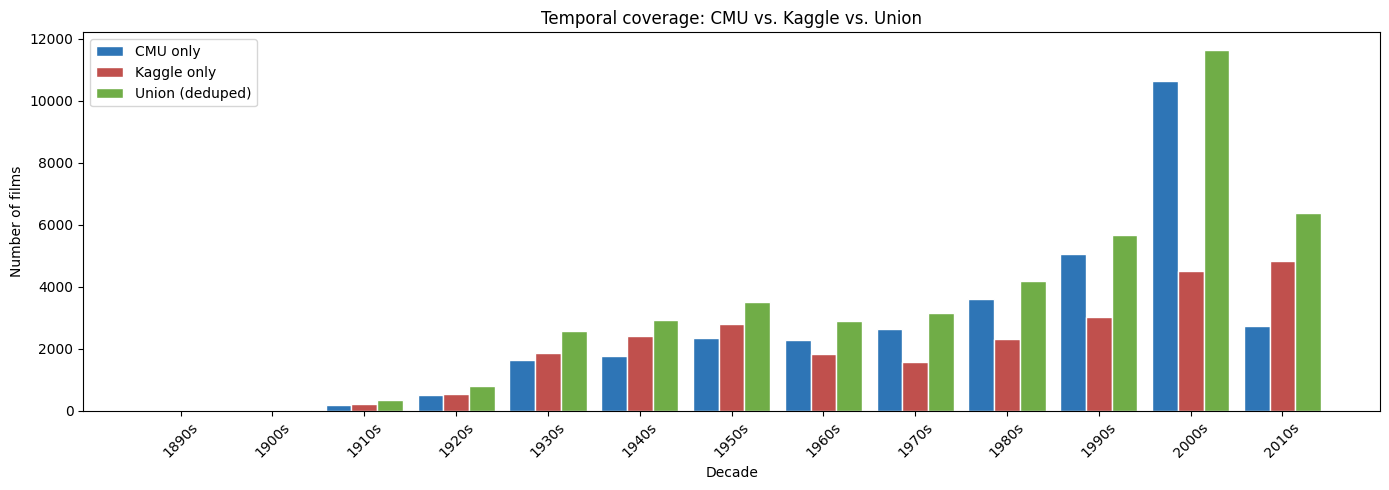

In [ ]:
# Decade comparison: union vs. the two source corpora
cmu_decades = cmu.dropna(subset=['decade']).groupby('decade').size()
kag_decades = kaggle.dropna(subset=['decade']).groupby('decade').size()
union_decades = union.dropna(subset=['decade']).groupby('decade').size()

all_decades = sorted(set(cmu_decades.index) | set(kag_decades.index) | set(union_decades.index))

fig, ax = plt.subplots(figsize=(14, 5))
width = 2.8
x = [float(d) for d in all_decades]
ax.bar([xi - width for xi in x], [cmu_decades.get(d, 0) for d in all_decades],
       width=width, label='CMU only', color='#2E75B6', edgecolor='white')
ax.bar(x, [kag_decades.get(d, 0) for d in all_decades],
       width=width, label='Kaggle only', color='#C0504D', edgecolor='white')
ax.bar([xi + width for xi in x], [union_decades.get(d, 0) for d in all_decades],
       width=width, label='Union (deduped)', color='#70AD47', edgecolor='white')
ax.set_xlabel('Decade')
ax.set_ylabel('Number of films')
ax.set_title('Temporal coverage: CMU vs. Kaggle vs. Union')
ax.legend()
ax.set_xticks(x)
ax.set_xticklabels([f'{int(d)}s' for d in all_decades], rotation=45)
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/union_decade_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

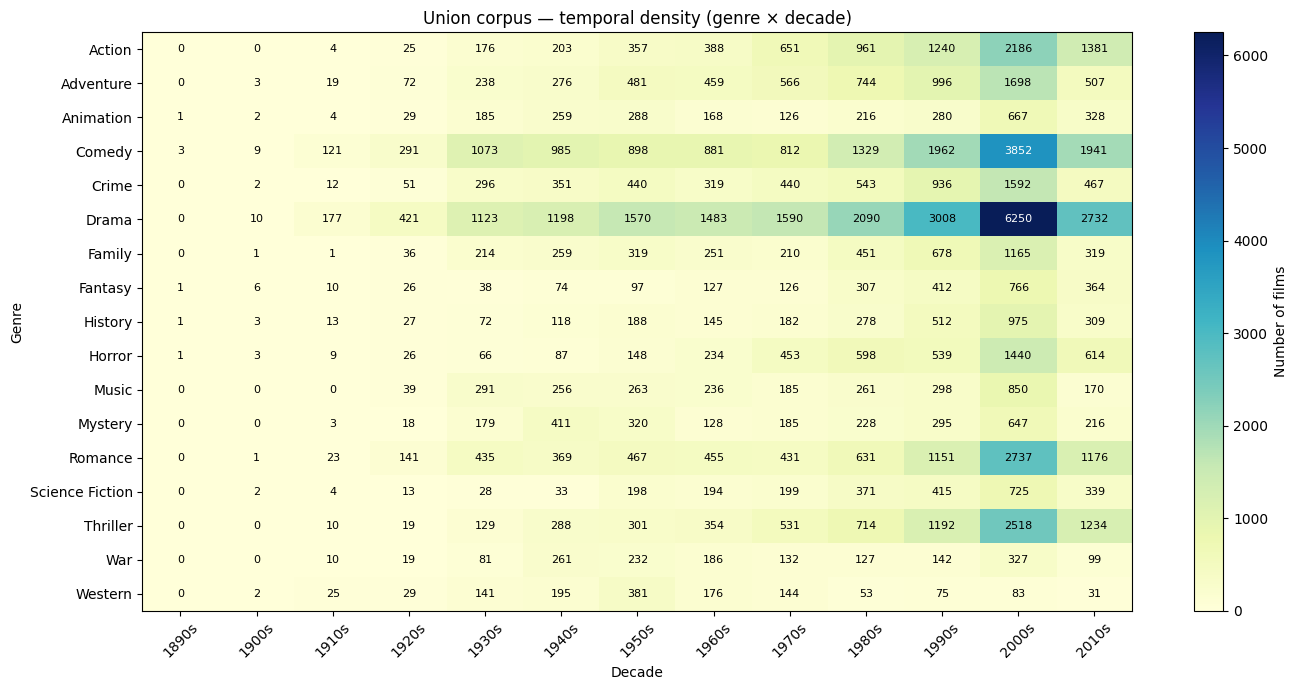


Cells with 1–29 films in the UNION:
  42 of 203 non-empty cells

Genres still thin in some decade after union:
  Action             thin in: 1910s, 1920s
  Adventure          thin in: 1900s, 1910s
  Animation          thin in: 1890s, 1900s, 1910s, 1920s
  Comedy             thin in: 1890s, 1900s
  Crime              thin in: 1900s, 1910s
  Drama              thin in: 1900s
  Family             thin in: 1900s, 1910s
  Fantasy            thin in: 1890s, 1900s, 1910s, 1920s
  History            thin in: 1890s, 1900s, 1910s, 1920s
  Horror             thin in: 1890s, 1900s, 1910s, 1920s
  Mystery            thin in: 1910s, 1920s
  Romance            thin in: 1900s, 1910s
  Science Fiction    thin in: 1900s, 1910s, 1920s, 1930s
  Thriller           thin in: 1910s, 1920s
  War                thin in: 1910s, 1920s
  Western            thin in: 1900s, 1910s, 1920s


In [ ]:
# Genre × decade heatmap on the union
exploded = (union[union['n_canonical_genres'] > 0]
            .dropna(subset=['decade'])
            .explode('genres_canonical'))

heatmap_union = exploded.pivot_table(
    index='genres_canonical',
    columns='decade',
    values='union_id',
    aggfunc='count',
    fill_value=0
)
heatmap_union = heatmap_union.reindex([g for g in CANONICAL_GENRES if g in heatmap_union.index])

fig, ax = plt.subplots(figsize=(14, 7))
im = ax.imshow(heatmap_union.values, aspect='auto', cmap='YlGnBu')
ax.set_xticks(range(len(heatmap_union.columns)))
ax.set_xticklabels([f'{int(d)}s' for d in heatmap_union.columns], rotation=45)
ax.set_yticks(range(len(heatmap_union.index)))
ax.set_yticklabels(heatmap_union.index)

vmax = heatmap_union.values.max()
for i in range(len(heatmap_union.index)):
    for j in range(len(heatmap_union.columns)):
        value = heatmap_union.values[i, j]
        color = 'white' if value > vmax * 0.5 else 'black'
        ax.text(j, i, f'{int(value)}', ha='center', va='center', color=color, fontsize=8)

plt.colorbar(im, ax=ax, label='Number of films')
ax.set_title('Union corpus — temporal density (genre × decade)')
ax.set_xlabel('Decade')
ax.set_ylabel('Genre')
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/union_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

# Flag thin cells in the union
THRESHOLD = 30
thin_cells = (heatmap_union > 0) & (heatmap_union < THRESHOLD)
print(f'\nCells with 1–{THRESHOLD-1} films in the UNION:')
print(f'  {thin_cells.sum().sum()} of {(heatmap_union > 0).sum().sum()} non-empty cells')
print(f'\nGenres still thin in some decade after union:')
for g in heatmap_union.index:
    thin_decades = [f'{int(d)}s' for d in heatmap_union.columns if thin_cells.loc[g, d]]
    if thin_decades:
        print(f'  {g:<18} thin in: {", ".join(thin_decades)}')

## 8. Save the Union Corpus

In [ ]:
# Drop the title_norm column (it was a working column, not for downstream use)
union_save = union.drop(columns=['title_norm'])

output_path = f'{OUTPUT_DIR}/movies_union.parquet'
union_save.to_parquet(output_path, engine='pyarrow', compression='snappy')

print(f'Saved union corpus:')
print(f'  Path:    {output_path}')
print(f'  Rows:    {len(union_save):,}')
print(f'  Size:    {os.path.getsize(output_path) / 1e6:.1f} MB')
print(f'  Columns: {list(union_save.columns)}')

Saved union corpus:
  Path:    /content/drive/MyDrive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational/v4_rebuild/01c_union/movies_union.parquet
  Rows:    45,958
  Size:    59.9 MB
  Columns: ['union_id', 'name', 'year', 'decade', 'plot', 'char_count', 'word_count', 'token_count', 'genres_canonical', 'n_canonical_genres', 'corpus_source', 'cmu_wiki_id', 'kaggle_wiki_id']


In [ ]:
# Write a compact union report
report_path = f'{OUTPUT_DIR}/union_report.txt'
with open(report_path, 'w') as f:
    f.write('UNION CORPUS REPORT\n')
    f.write('=' * 60 + '\n\n')
    f.write(f'Total films:       {len(union):,}\n')
    f.write(f'  CMU only:        {(union["corpus_source"] == "cmu").sum():,}\n')
    f.write(f'  Kaggle only:     {(union["corpus_source"] == "kaggle").sum():,}\n')
    f.write(f'  Both corpora:    {(union["corpus_source"] == "both").sum():,}\n\n')
    f.write(f'Year range: {int(union["year"].min())}–{int(union["year"].max())}\n')
    f.write(f'Films with valid year: {union["year"].notna().sum():,}\n\n')
    f.write('CANONICAL GENRE COUNTS\n')
    for genre in CANONICAL_GENRES:
        f.write(f'  {genre:<18} {union_canon[genre]:>6,}\n')

print(f'Wrote union report: {report_path}')

Wrote union report: /content/drive/MyDrive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational/v4_rebuild/01c_union/union_report.txt


## 9. Summary and Decisions for Notebook 02

The union corpus is now ready as the primary input for element extraction. Things to verify:

**Q1: Did the union size look right?** CMU (35,249) + Kaggle-only (~11,500 or so) should give roughly 46,000–47,000 total. If substantially smaller, the title matching was too loose and merged films that shouldn't have been merged. If substantially larger, the matching was too strict and left duplicates.

**Q2: Are there still thin cells in the union heatmap?** Compare to the CMU and Kaggle individual heatmaps. Where did the union close the gap, and where are genres still too thin for per-decade analysis?

**Q3: Source breakdown.** Look at the CMU/Kaggle/both split. If 'both' is much larger than expected, we may be over-matching. If 'both' is much smaller, the corpora are even more complementary than we thought.

**Next up: Notebook 02** loads `movies_union.parquet`, applies wiki markup cleaning (stripping `[[`, `]]`, templates), and runs the element extraction pipeline with the known spaCy bug fixes (singularization, stopword expansion, NER configuration). Element extraction is the start of the actual modeling work.